# Midterm Practice Notebook 2: Exploratory Data Analysis & Advanced PyTorch

Welcome to your second midterm practice! This notebook focuses on data generation without randomness, Exploratory Data Analysis (Lecture 6), and advanced PyTorch concepts (Lecture 8).

**How to use this notebook:**
1. Write your solution in the designated code blocks.
2. Run the cell.
3. If the `assert` statements pass without throwing an error, your code is correct!

## Task 1: Simulating Data for EDA (Using NumPy)

Before we can visualize data, we need a dataset. Let's use NumPy's structured generation tools from Lecture 4 to create a predictable dataset.

1. Generate an array named `study_hours` containing exactly 100 evenly spaced numbers starting from 0 and ending at 10. (Hint: Use a function designed to create a *linear space*).
2. Generate an array `exam_scores`. The score should be exactly $5 \times \text{study\_hours} + 40$.
3. Using a NumPy math function, create a `curved_scores` array by taking the square root of `exam_scores` and multiplying the result by 10.

In [2]:
import numpy as np
import pandas as pd

# TODO: Generate study_hours, exam_scores, and curved_scores
# endpoint: include last at stop
study_hours = np.linspace(start=0, stop=10, num=100, endpoint=True)
exam_scores = (5 * study_hours) + 40
curved_scores = np.sqrt(exam_scores) * 10


# --- ASSERTION BLOCK ---
assert 'study_hours' in locals(), "study_hours not defined."
assert 'exam_scores' in locals(), "exam_scores not defined."
assert 'curved_scores' in locals(), "curved_scores not defined."
assert len(study_hours) == 100, "study_hours must have 100 elements."
assert study_hours[0] == 0 and study_hours[-1] == 10, "study_hours must start at 0 and end at 10."
assert np.allclose(exam_scores, (study_hours * 5) + 40), "exam_scores calculated incorrectly."
assert np.allclose(curved_scores, np.sqrt(exam_scores) * 10), "curved_scores calculated incorrectly."
print("Task 1: Passed! ✓")

Task 1: Passed! ✓


## Task 2: Exploratory Data Analysis (EDA) - Histogram

According to Lecture 6, a **Histogram** is used to display the distribution of numerical data by grouping values into bins. It helps reveal shape, spread, and outliers.

Using `matplotlib.pyplot`, write code to plot a histogram of the `curved_scores`.
*(Note: Since plotting doesn't return variables easily testable by `assert`, we will just check that you imported the library correctly and leave a placeholder for your code!)*

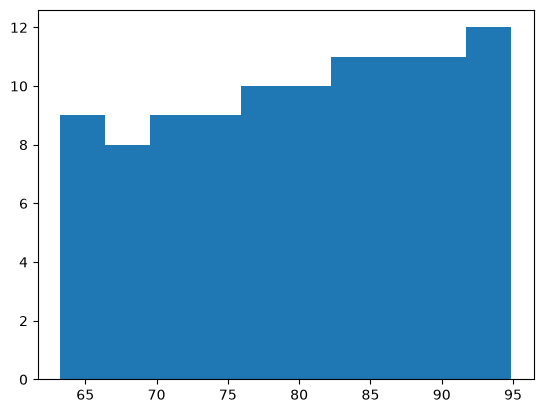

Task 2: Passed! ✓ (Check your plot visually!)


In [3]:
# TODO: Import matplotlib.pyplot as plt and plot a histogram of curved_scores
import matplotlib.pyplot as plt
plt.hist(curved_scores)
plt.show()

# --- ASSERTION BLOCK ---
assert 'plt' in locals(), "matplotlib.pyplot was not imported as 'plt'"
print("Task 2: Passed! ✓ (Check your plot visually!)")

## Task 3: Train/Test Split (Lecture 7)

We need to evaluate how a model performs on data it did not learn from. 

1. Combine `study_hours` (as features, X) and `curved_scores` (as targets, y). 
   *Hint: `study_hours` needs to be a 2D array for sklearn. Use `.reshape(-1, 1)`.*
2. Use `train_test_split` from Scikit-learn to split the data into `X_train`, `X_test`, `y_train`, and `y_test`.
3. Reserve 20% of the data for testing (`test_size=0.2`) and set `random_state=42`.

In [7]:
from sklearn.model_selection import train_test_split

# TODO: Reshape X and perform the train/test split
X = study_hours.reshape(-1, 1) #-1 means auto calculate rows or cols
print(X)
y = curved_scores
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



# --- ASSERTION BLOCK ---
assert 'X_train' in locals() and 'X_test' in locals(), "Split variables not defined."
assert X_train.shape == (80, 1), "X_train should have 80 rows and 1 column."
assert X_test.shape == (20, 1), "X_test should have 20 rows and 1 column."
assert y_train.shape == (80,), "y_train should have 80 elements."
print("Task 3: Passed! ✓")

[[ 0.        ]
 [ 0.1010101 ]
 [ 0.2020202 ]
 [ 0.3030303 ]
 [ 0.4040404 ]
 [ 0.50505051]
 [ 0.60606061]
 [ 0.70707071]
 [ 0.80808081]
 [ 0.90909091]
 [ 1.01010101]
 [ 1.11111111]
 [ 1.21212121]
 [ 1.31313131]
 [ 1.41414141]
 [ 1.51515152]
 [ 1.61616162]
 [ 1.71717172]
 [ 1.81818182]
 [ 1.91919192]
 [ 2.02020202]
 [ 2.12121212]
 [ 2.22222222]
 [ 2.32323232]
 [ 2.42424242]
 [ 2.52525253]
 [ 2.62626263]
 [ 2.72727273]
 [ 2.82828283]
 [ 2.92929293]
 [ 3.03030303]
 [ 3.13131313]
 [ 3.23232323]
 [ 3.33333333]
 [ 3.43434343]
 [ 3.53535354]
 [ 3.63636364]
 [ 3.73737374]
 [ 3.83838384]
 [ 3.93939394]
 [ 4.04040404]
 [ 4.14141414]
 [ 4.24242424]
 [ 4.34343434]
 [ 4.44444444]
 [ 4.54545455]
 [ 4.64646465]
 [ 4.74747475]
 [ 4.84848485]
 [ 4.94949495]
 [ 5.05050505]
 [ 5.15151515]
 [ 5.25252525]
 [ 5.35353535]
 [ 5.45454545]
 [ 5.55555556]
 [ 5.65656566]
 [ 5.75757576]
 [ 5.85858586]
 [ 5.95959596]
 [ 6.06060606]
 [ 6.16161616]
 [ 6.26262626]
 [ 6.36363636]
 [ 6.46464646]
 [ 6.56565657]
 [ 6.66666

## Task 4: PyTorch DataLoaders (Lecture 8)

In the previous practice, we built a `Dataset`. Now, let's focus on the `DataLoader`.

1. Create a simple custom dataset called `ScoreDataset` that takes `X_train` and `y_train`.
2. Instantiate it as `train_dataset`.
3. Create a `DataLoader` named `train_loader` that takes your `train_dataset`.
4. Set the `batch_size` to 16, and ensure `shuffle=True` (as recommended for training data in the slides).

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader

class ScoreDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32) # Regression target is usually float
        
    def __len__(self):
        return len(self.X)
        
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# TODO: Instantiate the dataset and create the DataLoader

train_dataset = ScoreDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)



# --- ASSERTION BLOCK ---
assert 'train_loader' in locals(), "train_loader not defined."
assert isinstance(train_loader, DataLoader), "Must be a PyTorch DataLoader object."
assert train_loader.batch_size == 16, "Batch size must be exactly 16."
assert train_loader.dataset == train_dataset, "DataLoader must wrap the train_dataset."

# Check the first batch
batch_x, batch_y = next(iter(train_loader))
assert batch_x.shape == (16, 1), "The batched X should have shape (16, 1)."
assert batch_y.shape == (16,), "The batched y should have shape (16,)."
print("Task 4: Passed! ✓ You have mastered batches!")

Task 4: Passed! ✓ You have mastered batches!
